In [1]:
from torch_geometric.datasets import Planetoid, CitationFull
from torch_geometric.transforms import NormalizeFeatures
import numpy as np

import toponetx as tnx
import networkx as nx
import itertools
from torch_geometric.utils import to_networkx,to_undirected, sort_edge_index
from toponetx.utils.normalization import compute_bunch_normalized_matrices,compute_laplacian_normalized_matrix
from toponetx.utils.normalization import *
import scipy.sparse.linalg as spl
from numpy.linalg import pinv
from scipy import sparse
from scipy.sparse import csr_matrix
import torch
from topomodelx.utils.sparse import from_sparse
from topomodelx.base.aggregation import Aggregation
from topomodelx.base.conv import Conv
import jax.numpy as jnp
import scipy.sparse.linalg as spl
from scipy.sparse import csr_matrix, diags
import torch_geometric.transforms as T



#Cora = Planetoid(root='data/Planetoid', name='Cora', transform=NormalizeFeatures())

In [17]:
transform = T.Compose([T.RemoveIsolatedNodes(), T.ToUndirected(), T.NormalizeFeatures()])
CiteSeer = Planetoid(root='data/Planetoid', name='CiteSeer', transform=transform, split = "full")
data = CiteSeer[0]

def find_cliques_size_k(G, k):
    all_cliques = set()
    for clique in nx.find_cliques(G):
        if len(clique) == k:
            all_cliques.add(tuple(sorted(clique)))
        elif len(clique) > k:
            for mini_clique in itertools.combinations(clique, k):
                all_cliques.add(tuple(sorted(mini_clique)))
    return list(all_cliques)

In [19]:
G = to_networkx(data, to_undirected = True)
face_set = find_cliques_size_k(G,3)
edge_set = np.array(sort_edge_index(data.edge_index)).T
sc = tnx.SimplicialComplex(list(edge_set) + face_set)

In [20]:
def easy_inverse_matrix(D):
    diagonal_elements = np.diag(D)
    diagonal_elements_inv = 1/diagonal_elements
    diagonal_elements_inv[np.isinf(diagonal_elements_inv) | np.isneginf(diagonal_elements_inv)] = 0
    D_inv = np.diag(diagonal_elements_inv, 0)
    return D_inv
    
def compute_bunch_normalized_matrices(
    B1: np.ndarray | csr_matrix, B2: np.ndarray | csr_matrix
) -> tuple[
    np.ndarray | csr_matrix,
    np.ndarray | csr_matrix,
    np.ndarray | csr_matrix,
    np.ndarray | csr_matrix,
]:
    """Get Bunch normalization.

    Parameters
    ----------
    B1 : np.ndarray or csr_matrix
        The boundary B1: C1->C0 of a complex.
    B2 : np.ndarray or csr_matrix
        The boundary B2: C2->C1 of a complex.

    Returns
    -------
    B1 : np.ndarray or csr_matrix
        Normalized B1: C1->C0.
    B1T : np.ndarray or csr_matrix
        Normalized B1T: C0->C1.
    B2 : np.ndarray or csr_matrix
        Normalized B2: C2->C1.
    B2T : np.ndarray or csr_matrix
        Normalized B2T: C1->C2.

    References
    ----------
    .. [1] Schaub, Benson, Horn, Lippner, Jadbabaie.
        Random walks on simplicial complexes and the normalized hodge 1-laplacian.
        Paper: https://epubs.siam.org/doi/10.1137/18M1201019

    .. [2] Bunch, You, Fung, Singh.
        Simplicial 2-Complex Convolutional Neural Networks.
        Paper: https://openreview.net/forum?id=TLbnsKrt6J-
    """
    B1N = _compute_B1_normalized_matrix(B1, B2)
    B1TN = _compute_B1T_normalized_matrix(B1, B2)
    B2N = _compute_B2_normalized_matrix(B2)
    B2TN = _compute_B2T_normalized_matrix(B2)
    return B1N, B1TN, B2N, B2TN


def _compute_B1_normalized_matrix(
    B1: np.ndarray | csr_matrix, B2: np.ndarray | csr_matrix
) -> np.ndarray | csr_matrix:
    """Compute normalized boundary matrix B1.

    Parameters
    ----------
    B1 : np.ndarray or csr_matrix
        The boundary B1: C1->C0 of a complex.
    B2 : np.ndarray or csr_matrix
        The boundary B2: C2->C1 of a complex.

    Returns
    -------
    np.ndarray or csr_matrix
        Normalized B1: C1->C0.
    """
    D2 = _compute_D2(B2)
    D1 = _compute_D1(B1, D2)
    if isinstance(B1, np.ndarray):
        #D1_pinv = pinv(D1)
        D1_inv = easy_inverse_matrix(D1)
    elif isinstance(B1, csr_matrix):
        #D1_pinv = csr_matrix(pinv(D1.toarray()))
        D1_inv = csr_matrix(easy_inverse_matrix(D1.toarray()))

    return D1_inv @ B1
    #return D1_pinv @ B1


def _compute_B1T_normalized_matrix(
    B1: np.ndarray | csr_matrix, B2: np.ndarray | csr_matrix
) -> np.ndarray | csr_matrix:
    """Compute normalized transpose boundary matrix B1T.

    Parameters
    ----------
    B1 : np.ndarray or csr_matrix
        The boundary B1: C1->C0  of a complex.
    B2 : np.ndarray or csr_matrix
        The boundary B2: C2->C1  of a complex.

    Returns
    -------
    np.ndarray or csr_matrix
        Normalized transpose boundary matrix B1T: C0->C1.
        This is the coboundary C0->C1.
    """
    D2 = _compute_D2(B2)
    D1 = _compute_D1(B1, D2)
    if isinstance(B1, np.ndarray):
        #D1_pinv = pinv(D1)
        D1_inv = easy_inverse_matrix(D1)
    elif isinstance(B1, csr_matrix):
        #D1_pinv = csr_matrix(pinv(D1.toarray()))
        D1_inv = csr_matrix(easy_inverse_matrix(D1.toarray()))
    else:
        raise TypeError("input type must be either np.ndarray or csr_matrix")
    return D2 @ B1.T @ D1_inv
    #return D2 @ B1.T @ D1_pinv


def _compute_B2_normalized_matrix(
    B2: np.ndarray | csr_matrix,
) -> np.ndarray | csr_matrix:
    """Compute normalized boundary matrix B2.

    Parameters
    ----------
    B2 : np.ndarray or csr_matrix
        The boundary matrix B2: C2 -> C1 of a simplicial complex.

    Returns
    -------
    np.ndarray or csr_matrix
        Normalized boundary matrix B2: C2 -> C1.
    """
    D3 = _compute_D3(B2)
    return B2 @ D3


def _compute_B2T_normalized_matrix(
    B2: np.ndarray | csr_matrix,
) -> np.ndarray | csr_matrix:
    """Compute normalized transpose matrix operator B2T.

    Parameters
    ----------
    B2 : np.ndarray or csr_matrix
        The boundary B2: C2->C1.

    Returns
    -------
    np.ndarray or csr_matrix
        Normalized transpose matrix operator B2T: C1->C2.
        This is the coboundary matrix: C1->C2.
    """
    D5 = _compute_D5(B2)
    if isinstance(B2, np.ndarray):
        #D5_pinv = pinv(D5)
        D5_inv = easy_inverse_matrix(D5)
        #return B2.T @ D5_pinv
        return B2.T @ D5_inv
    if isinstance(B2, csr_matrix):
        #D5_pinv = csr_matrix(pinv(D5.toarray()))
        D5_inv = csr_matrix(easy_inverse_matrix(D5.toarray()))
        #return B2.T @ D5_pinv
        return B2.T @ D5_inv
    raise TypeError("input type must be either np.ndarray or csr_matrix")


def _compute_D1(B1: np.ndarray | csr_matrix, D2: diags) -> diags:
    """Compute the degree matrix D1.

    Parameters
    ----------
    B1 : np.ndarray or csr_matrix
        The boundary B1: C1->C0 of a complex.
    D2 : diags
        The degree matrix D2.

    Returns
    -------
    diags
        Normalized degree matrix D1.
    """
    if isinstance(B1, csr_matrix):
        rowsum = np.array((np.abs(B1) @ D2).sum(axis=1)).flatten()
        return 2 * diags(rowsum)
    if isinstance(B1, np.ndarray):
        rowsum = (np.abs(B1) @ D2).sum(axis=1)
        return 2 * np.diag(rowsum)
    raise TypeError("Input type must be either np.ndarray or csr_matrix.")


def _compute_D2(B2: np.ndarray | csr_matrix) -> diags:
    """Compute the degree matrix D2.

    Parameters
    ----------
    B2 : np.ndarray or csr_matrix
        The boundary matrix B2: C2 -> C1 of a simplicial complex.

    Returns
    -------
    diags
        Normalized degree matrix D2.
    """
    if isinstance(B2, csr_matrix):
        rowsum = np.array(np.abs(B2).sum(axis=1)).flatten()
        return diags(np.maximum(rowsum, 1))
    if isinstance(B2, np.ndarray):
        rowsum = np.abs(B2).sum(axis=1)
        return np.diag(np.maximum(rowsum, 1))
    raise TypeError("Input type must be either np.ndarray or csr_matrix.")


def _compute_D3(B2: np.ndarray | csr_matrix) -> diags:
    """Compute the degree matrix D3.

    Parameters
    ----------
    B2 : np.ndarray or csr_matrix
        The boundary matrix B2: C2 -> C1 of a simplicial complex.

    Returns
    -------
    diags
        Degree matrix D3.
    """
    if isinstance(B2, csr_matrix):
        return diags(np.ones(B2.shape[1]) / 3)
    if isinstance(B2, np.ndarray):
        return np.diag(np.ones(B2.shape[1]) / 3)
    raise TypeError("Input type must be either np.ndarray or csr_matrix.")


def _compute_D5(B2: np.ndarray | csr_matrix) -> diags:
    """Compute the degree matrix D5.

    Parameters
    ----------
    B2 : np.ndarray or csr_matrix
        The boundary matrix B2: C2 -> C1 of a simplicial complex.

    Returns
    -------
    diags
        Normalized degree matrix D5.
    """
    if isinstance(B2, csr_matrix):
        rowsum = np.array(np.abs(B2).sum(axis=1)).flatten()
        return diags(rowsum)
    if isinstance(B2, np.ndarray):
        rowsum = np.abs(B2).sum(axis=1)
        return np.diag(rowsum)
    raise TypeError("Input type must be either np.ndarray or csr_matrix.")

In [21]:
def normalized_high_order_adjcency(B1, B2):
    # L0
    L0 = B1@B1.T
    B1_sum = np.abs(B1).sum(axis=1)
    D0 = sparse.diags(B1_sum.reshape(-1), 0)
    B1_sum_inv = 1./B1_sum
    B1_sum_inv[np.isinf(B1_sum_inv) | np.isneginf(B1_sum_inv)] = 0
    D0_inv = np.diag(B1_sum_inv.reshape(-1), 0)
    L0 = D0_inv@L0
    L0factor = (-1)*np.diag((1/(B1_sum_inv + 1)).reshape(-1), 0)
    L0bias = np.eye(D0.shape[0])
    L0 = L0factor@L0 + L0bias

    #L1
    A_1u = _compute_D2(B2) - B2@_compute_D3(B2)@B2.T

    #A_1d = pinv(_compute_D2(B2)) - B1.T@pinv(_compute_D1(B1, _compute_D2(B2)))@B1
    A_1d = easy_inverse_matrix(_compute_D2(B2)) - B1.T@easy_inverse_matrix(_compute_D1(B1, _compute_D2(B2)))@B1
    #easy_inverse_matrix
    
    A_1u_norm = (
            A_1u
            +
            np.eye(A_1u.shape[0])
    )@np.diag(1/_compute_D2(B2).diagonal()+1, 0)
    
    A_1d_norm = (
        _compute_D2(B2)
        +
        np.eye(_compute_D2(B2).shape[0])
    )@(A_1d + np.eye(A_1d.shape[0]))
    
    L1 = A_1u_norm + A_1d_norm
    
    #L2
    #A_2d = np.eye(B2.shape[1]) - B2.T@pinv(_compute_D5(B2))@B2
    A_2d = np.eye(B2.shape[1]) - B2.T@easy_inverse_matrix(_compute_D5(B2))@B2
    
    L2 = (2*np.eye(B2.shape[1]))@(A_2d + np.eye(A_2d.shape[0]))

    return L0, L1, L2

In [22]:
B1 = sc.incidence_matrix(1)#.todense().A

B2 = sc.incidence_matrix(2)#.todense().A

In [23]:
B1_norm, B1T_norm, B2_norm, B2T_norm = compute_bunch_normalized_matrices(B1, B2)

L0, L1, L2 = normalized_high_order_adjcency(B1.todense().A, B2.todense().A)

/var/folders/2s/s7d6qfbj0fb415tqwkd_3qkm0000gn/T/ipykernel_18960/1603304198.py:3: RuntimeWarning: divide by zero encountered in divide
  diagonal_elements_inv = 1/diagonal_elements


In [24]:
data.x.shape

torch.Size([3279, 3703])

In [25]:
B1_norm.shape

(3279, 4552)

In [26]:
B1_norm = from_sparse(B1_norm)
B1T_norm = from_sparse(B1T_norm)
B2_norm = from_sparse(B2_norm)
B2T_norm = from_sparse(B2T_norm)

L0 = torch.Tensor(L0).to_sparse_coo()
L1 = torch.Tensor(L1).to_sparse_coo()
L2 = torch.Tensor(L2).to_sparse_coo()

In [27]:
class SCConvLayer(torch.nn.Module):

    def __init__(self, hidden_channels, node_channels, edge_channels, face_channels) -> None:
        super().__init__()

        self.node_channels = node_channels
        self.edge_channels = edge_channels
        self.face_channels = face_channels
        self.hidden_channels = hidden_channels

        #self.ln = torch.nn.Linear(self.node_channels, hidden_channels)

        self.conv_0_to_0 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )
        self.conv_0_to_1 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )

        self.conv_1_to_1 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )
        self.conv_1_to_0 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )

        self.conv_1_to_2 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )

        self.conv_2_to_1 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )

        self.conv_2_to_2 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )

        self.conv_HSN_0_to_0 = Conv(
            in_channels=hidden_channels,
            out_channels=hidden_channels,
            update_func="relu",
        )
        
        self.conv_HSN_1_to_0 = Conv(
            in_channels=self.hidden_channels,
            out_channels=self.hidden_channels,
            update_func="relu",
        )
        #self.bn1 = torch.nn.BatchNorm1d(self.node_channels)
        #self.bn2 = torch.nn.BatchNorm1d(self.edge_channels)
        #self.bn3 = torch.nn.BatchNorm1d(self.edge_channels)
        #self.bn4 = torch.nn.BatchNorm1d(self.node_channels)
        #self.bn5 = torch.nn.BatchNorm1d(self.face_channels)
        #self.bn6 = torch.nn.BatchNorm1d(self.edge_channels)
        #self.bn7 = torch.nn.BatchNorm1d(self.face_channels)

        self.aggr_on_nodes = Aggregation(aggr_func="sum", update_func="relu")
        self.aggr_on_edges = Aggregation(aggr_func="sum", update_func="relu")
        self.aggr_on_faces = Aggregation(aggr_func="sum", update_func="relu")
        
        self.aggr_on_nodes_HSN = Aggregation(aggr_func="sum", update_func="relu")


    def forward(
        self,
        x_0,
        B1,
        B1T,
        B2,
        B2T,
        L0,
        L1,
        L2
    ):
        #print(x_0.shape)
        #h_0 = self.ln(x_0)
        
        x0_0_0 = self.conv_0_to_0(x_0, L0)
        x0_0_1 = self.conv_0_to_1(x_0, B1T)
        x0_1_2 = self.conv_1_to_2(x0_0_1, B2T)

        
        x1_1_0 = self.conv_1_to_0(x0_0_1, B1)
        x1_1_1 = self.conv_1_to_1(x0_0_1, L1)
        x1_1_2 = self.conv_1_to_2(x0_0_1, B2T)

        #adj_norm = adjacency_down_1_norm.add(adjacency_up_1_norm)

        x2_2_1 = self.conv_2_to_1(x0_1_2, B2)
        #x2_1_2 = self.conv_1_to_2(x0_1_2, B2T)
        x2_2_2 = self.conv_2_to_2(x0_1_2, L2)

       # x0_0_0 = self.bn1()
       # x1_1_0 = self.bn2()
       # x0_0_1 = self.bn3()
       # x1_1_1 = self.bn4()
       # x2_2_1 = self.bn5()
       # x1_1_2 = self.bn6()
       # x2_2_2 = self.bn7()
    
        x0_level1_out = self.aggr_on_nodes([x0_0_0, x1_1_0])
        x1_level1_out = self.aggr_on_edges([x0_0_1, x1_1_1, x2_2_1])
        x2_level1_out = self.aggr_on_faces([x1_1_2, x2_2_2])



        #HSN
        
        x0_HSN_0_0 = self.conv_HSN_0_to_0(x0_level1_out, L0)
        x0_HSN_1_0 = self.conv_HSN_1_to_0(x1_level1_out, B1)
        x0_HSN_out = self.aggr_on_nodes_HSN([x0_HSN_0_0, x0_HSN_1_0])
        
        return x0_HSN_out



In [28]:
import torch.nn.functional as F

class SCConv(torch.nn.Module):
    def __init__(
        self, hidden_channels, node_channels, edge_channels=None, face_channels=None, n_layers=2
    ):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.node_channels = node_channels
        self.edge_channels = node_channels if edge_channels is None else edge_channels
        self.face_channels = node_channels if face_channels is None else face_channels
        self.n_layers = n_layers
        
        self.ln = torch.nn.Linear(self.node_channels, hidden_channels)
        self.layers = torch.nn.ModuleList(
            SCConvLayer(
                hidden_channels = self.hidden_channels,
                node_channels=self.node_channels,
                edge_channels=self.edge_channels,
                face_channels=self.face_channels,
            )
            for _ in range(n_layers)
        )

    def forward(
        self,
        x_0,
        B1,
        B1T,
        B2,
        B2T,
        L0,
        L1,
        L2
    ):
        h_0 = self.ln(x_0)
        h_0 = h_0.relu()
        h_0 = F.dropout(h_0, p=0.5, training=self.training)
        
        for i in range(self.n_layers):
            h_0 = self.layers[i](
                h_0,
                B1,
                B1T,
                B2,
                B2T,
                L0,
                L1,
                L2
            )

        return h_0

In [31]:
class Network(torch.nn.Module):
    def __init__(self, hidden_channels = 128, out_channels = 6, n_layers= 2):
        super().__init__()
       # torch.manual_seed(1234567)
        self.base_model = SCConv(
            hidden_channels=hidden_channels,
            node_channels=data.num_features,
            n_layers=n_layers,
        )
        self.linear_x0 = torch.nn.Linear(hidden_channels, out_channels)
        #self.linear_x1 = torch.nn.Linear(data.num_features, out_channels)
        #self.linear_x2 = torch.nn.Linear(data.num_features, out_channels)

    def forward(self, x_0,
                        B1,
                        B1T,
                        B2,
                        B2T,
                        L0,
                        L1,
                        L2):
        x_0 = self.base_model(
            x_0,
            B1,
            B1T,
            B2,
            B2T,
            L0,
            L1,
            L2
        )
        x_0 = self.linear_x0(x_0)
        return x_0

model = Network()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=5e-4)
criterion = torch.nn.CrossEntropyLoss()
print(model)

Network(
  (base_model): SCConv(
    (ln): Linear(in_features=3703, out_features=128, bias=True)
    (layers): ModuleList(
      (0-1): 2 x SCConvLayer(
        (conv_0_to_0): Conv()
        (conv_0_to_1): Conv()
        (conv_1_to_1): Conv()
        (conv_1_to_0): Conv()
        (conv_1_to_2): Conv()
        (conv_2_to_1): Conv()
        (conv_2_to_2): Conv()
        (conv_HSN_0_to_0): Conv()
        (conv_HSN_1_to_0): Conv()
        (aggr_on_nodes): Aggregation()
        (aggr_on_edges): Aggregation()
        (aggr_on_faces): Aggregation()
        (aggr_on_nodes_HSN): Aggregation()
      )
    )
  )
  (linear_x0): Linear(in_features=128, out_features=6, bias=True)
)


In [32]:
test_interval = 10
num_epochs = 400

for epoch_i in range(1, num_epochs + 1):
    epoch_loss = []
    model.train()
    optimizer.zero_grad()
    #print(data.x.shape)
    y_hat = model(
            data.x,
            B1_norm,
            B1T_norm,
            B2_norm,
            B2T_norm,
            L0,
            L1,
            L2
    )
    loss = criterion(y_hat[data.train_mask], data.y[data.train_mask])
    epoch_loss.append(loss.item())
    loss.backward()
    optimizer.step()

    pred = y_hat.argmax(dim=1)
    train_correct = pred[data.train_mask] == data.y[data.train_mask]
    accuracy = int(train_correct.sum()) / int(data.train_mask.sum())
    
    print(
        f"Epoch: {epoch_i} loss: {np.mean(epoch_loss):.4f} Train_acc: {accuracy:.4f}",
        flush=True,
    )

    if epoch_i % test_interval == 0:
        with torch.no_grad():
            model.eval()
            out = model(data.x,
            B1_norm,
            B1T_norm,
            B2_norm,
            B2T_norm,
            L0,
            L1,
            L2)
            pred = out.argmax(dim=1)  # Use the class with highest probability.
            test_correct = pred[data.test_mask] == data.y[data.test_mask]  # Check against ground-truth labels.
            test_accuracy = int(test_correct.sum()) / int(data.test_mask.sum())  # Derive ratio of correct predictions.
            print(f"Test_acc: {test_accuracy:.4f}", flush=True)

Epoch: 1 loss: 1.7911 Train_acc: 0.1942
Epoch: 2 loss: 1.7801 Train_acc: 0.2237
Epoch: 3 loss: 1.7590 Train_acc: 0.1970
Epoch: 4 loss: 1.7628 Train_acc: 0.2026
Epoch: 5 loss: 1.7383 Train_acc: 0.2543
Epoch: 6 loss: 1.7367 Train_acc: 0.2270
Epoch: 7 loss: 1.7196 Train_acc: 0.2231
Epoch: 8 loss: 1.6834 Train_acc: 0.2410
Epoch: 9 loss: 1.6263 Train_acc: 0.2738
Epoch: 10 loss: 1.5567 Train_acc: 0.3144
Test_acc: 0.2955
Epoch: 11 loss: 1.4844 Train_acc: 0.3406
Epoch: 12 loss: 1.4254 Train_acc: 0.4329
Epoch: 13 loss: 1.3807 Train_acc: 0.4741
Epoch: 14 loss: 1.3334 Train_acc: 0.4836
Epoch: 15 loss: 1.3068 Train_acc: 0.5454
Epoch: 16 loss: 1.2558 Train_acc: 0.5281
Epoch: 17 loss: 1.1702 Train_acc: 0.5821
Epoch: 18 loss: 1.1447 Train_acc: 0.5843
Epoch: 19 loss: 1.0304 Train_acc: 0.6817
Epoch: 20 loss: 0.9603 Train_acc: 0.6711
Test_acc: 0.5769
Epoch: 21 loss: 0.8985 Train_acc: 0.6767
Epoch: 22 loss: 0.8603 Train_acc: 0.6939
Epoch: 23 loss: 0.9932 Train_acc: 0.6433
Epoch: 24 loss: 1.3755 Train_acc

In [33]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def visualize(h, color):
    z = TSNE(n_components=2, n_jobs=-1).fit_transform(h.detach().cpu().numpy())

    plt.figure(figsize=(10,10))
    plt.xticks([])
    plt.yticks([])

    plt.scatter(z[:, 0], z[:, 1], s=70, c=color, cmap="Set2")
    plt.show()

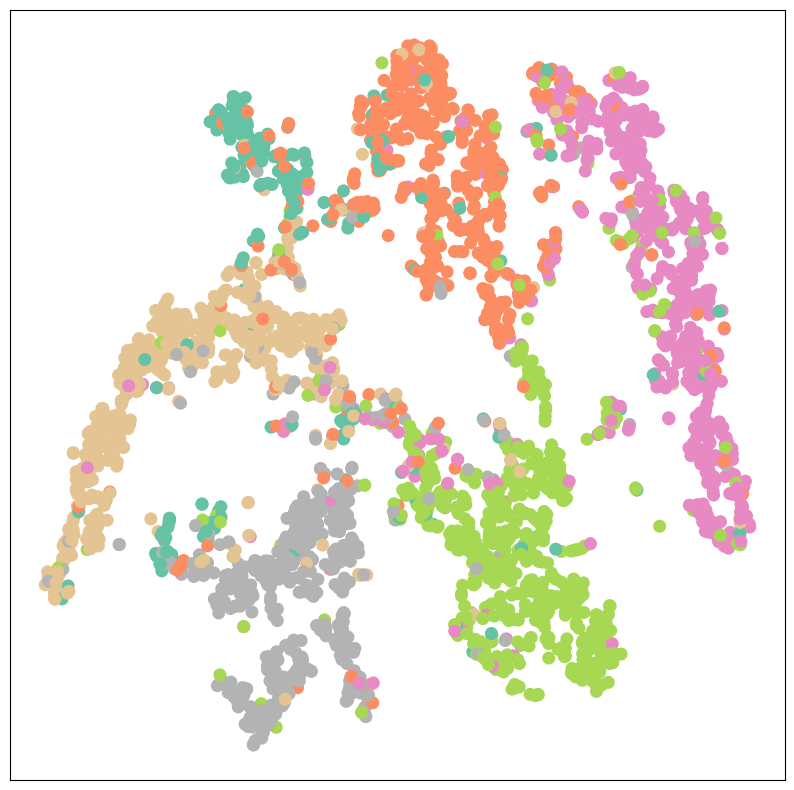

In [34]:
model.eval()

out = model(data.x,
            B1_norm,
            B1T_norm,
            B2_norm,
            B2T_norm,
            L0,
            L1,
            L2)
visualize(out, color=data.y)